# Task 2: Exploratory Data Analysis (EDA)

## AI & ML Internship

### Objective
To understand and analyze data using statistical methods and visualizations by identifying patterns, trends, relationships, and anomalies in the dataset.

### Dataset
Customer Shopping Trends Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files
uploaded = files.upload()

Saving shopping_trends.csv to shopping_trends.csv


In [3]:
df = pd.read_csv('shopping_trends.csv')
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (3900, 18)

Column Names:
['Customer ID', 'Age', 'Gender', 'Item Purchased', 'Category', 'Purchase Amount (USD)', 'Location', 'Size', 'Color', 'Season', 'Review Rating', 'Subscription Status', 'Shipping Type', 'Discount Applied', 'Promo Code Used', 'Previous Purchases', 'Payment Method', 'Frequency of Purchases']

Missing Values:
Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64

Total Missing Values: 0

Duplicate Rows: 0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3900 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [6]:
df.describe()

,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.749949,25.351538
std,1125.977353,15.207589,23.685392,0.716223,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.700000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


In [7]:
df.describe(include='object')

,Gender,Item Purchased,Category,Location,Size,Color,Season,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Payment Method,Frequency of Purchases
count,3900,3900,3900,3900,3900,3900,3900,3900,3900,3900,3900,3900,3900
unique,2,25,4,50,4,25,4,2,6,2,2,6,7
top,Male,Blouse,Clothing,Montana,M,Olive,Spring,No,Free Shipping,No,No,PayPal,Every 3 Months
freq,2652,171,1737,96,1755,177,999,2847,675,2223,2223,677,584


## 1. Data Visualization

###  Histograms of Numerical Features

Histograms are used to understand the distribution and frequency of numerical data. They help identify patterns, concentration of values, and skewness in the dataset.

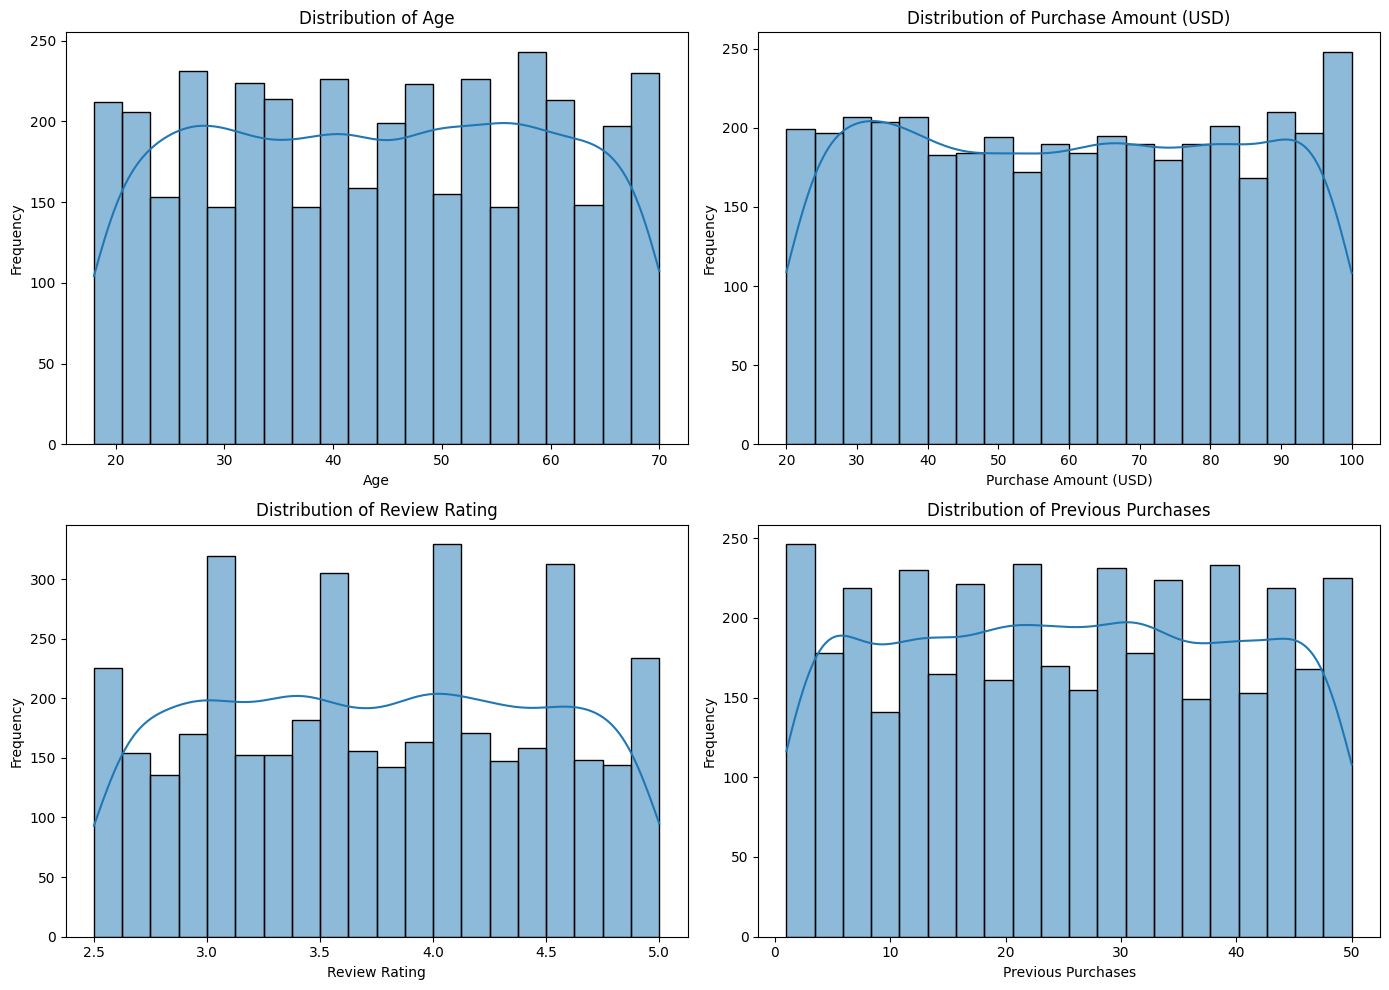

In [9]:
numeric_cols =[
    'Age',
    'Purchase Amount (USD)',
    'Review Rating',
    'Previous Purchases'
]

plt.figure(figsize=(14,10))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 2, i)
    sns.histplot(df[col], bins=20, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

###  2. Boxplots of Numerical Features

Boxplots are used to visualize the distribution of numerical data and identify potential outliers. They display the median, quartiles, and spread of values.

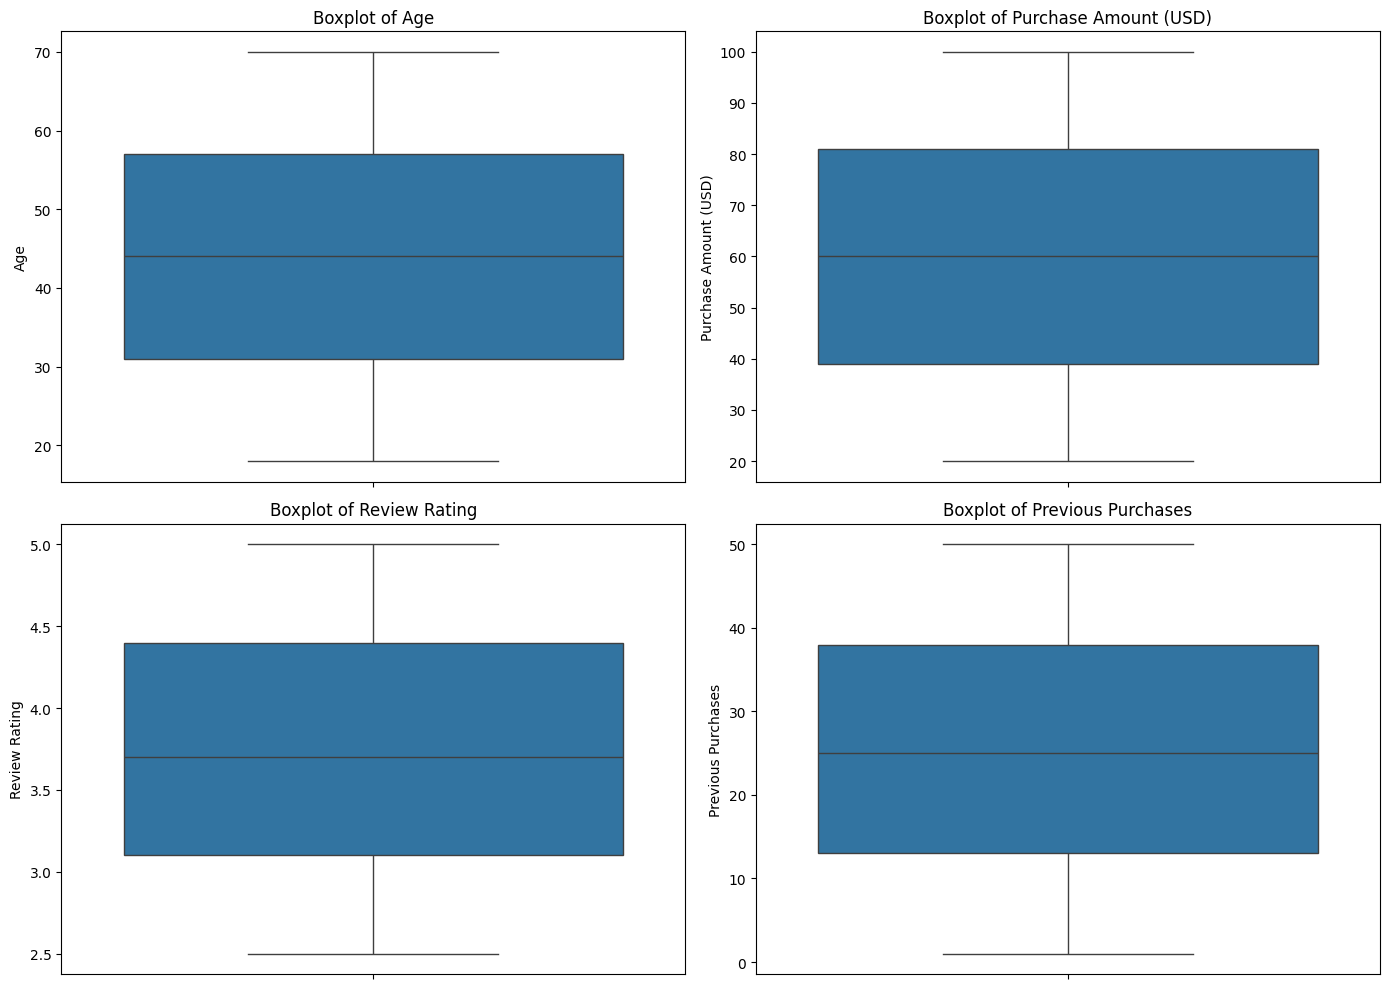

In [10]:
plt.figure(figsize=(14, 10))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

### 3.1 Correlation Matrix

A correlation matrix is used to identify the strength and direction of relationships between numerical features. It helps understand how different variables are related to each other.

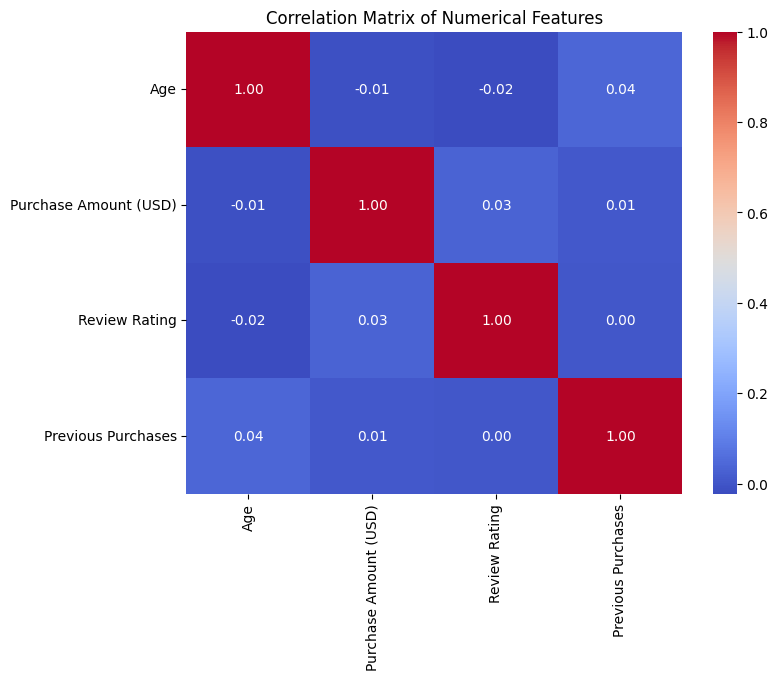

In [11]:
correlation = df[numeric_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

### 3.2 Pairplot of Numerical Features

A pairplot is used to visualize relationships between multiple numerical variables. It displays scatter plots between different features and distributions along the diagonal.

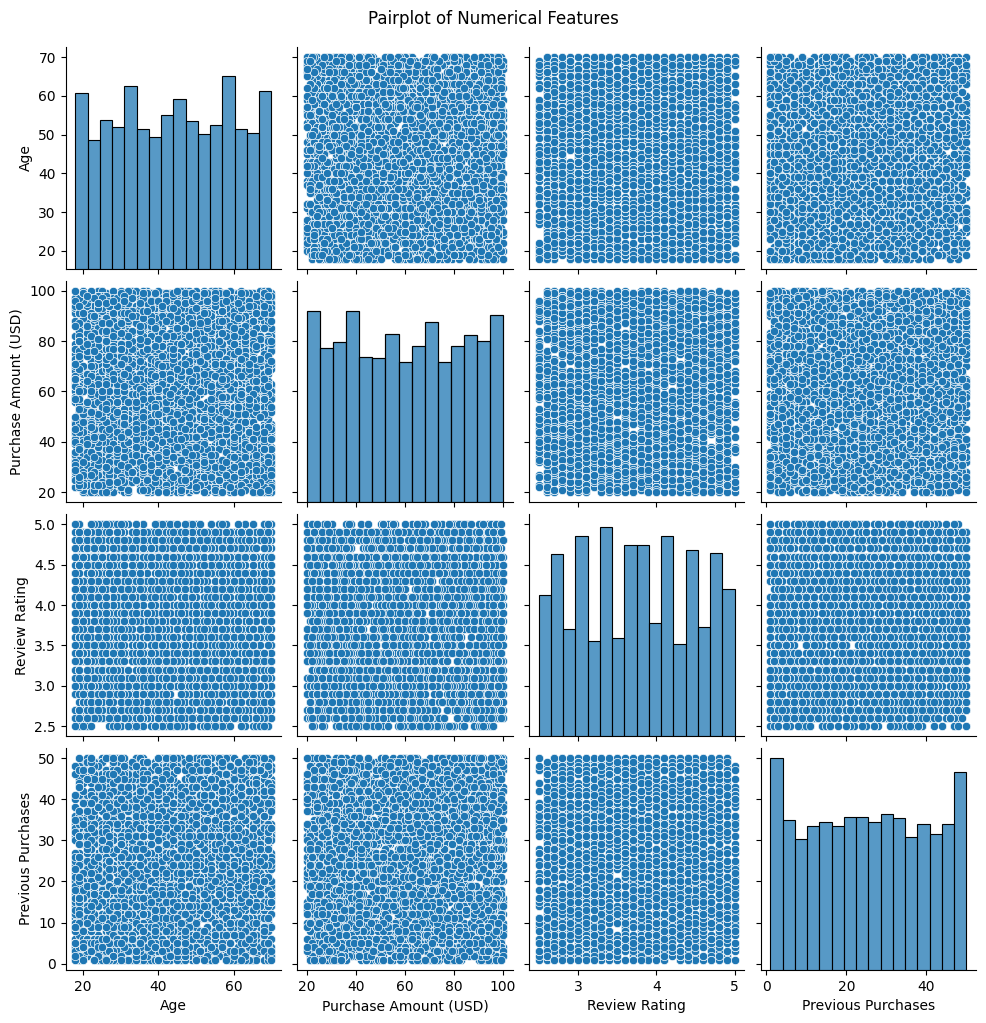

In [12]:
sns.pairplot(df[numeric_cols], diag_kind='hist')
plt.suptitle('Pairplot of Numerical Features', y=1.02)
plt.show()

###  Analysis of Categorical Features

Categorical analysis helps understand customer preferences by examining the frequency and distribution of different categories.

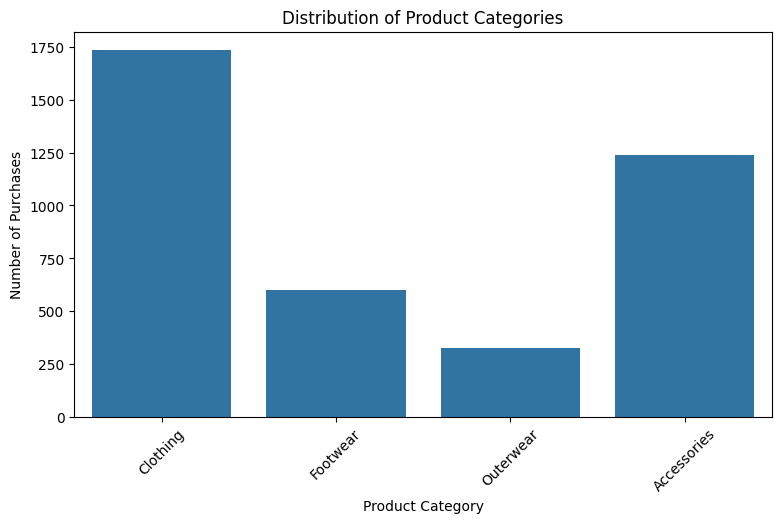

In [13]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='Category')
plt.title('Distribution of Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Number of Purchases')
plt.xticks(rotation=45)
plt.show()

###  Seasonal Shopping Distribution

This analysis examines customer purchasing activity across different seasons to identify seasonal shopping patterns and preferences.

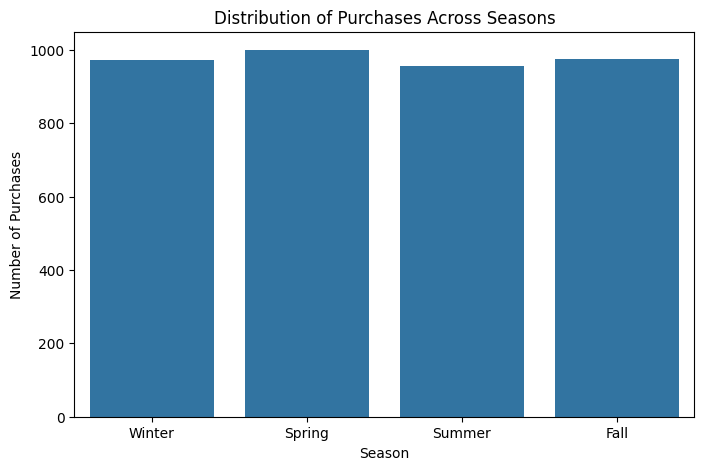

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Season')

plt.title('Distribution of Purchases Across Seasons')
plt.xlabel('Season')
plt.ylabel('Number of Purchases')

plt.show()

## 4. Patterns, Trends and Anomalies

This section focuses on identifying important patterns, trends, and unusual observations from the statistical analysis and visualizations.

### Observations

1. The dataset contains 3,900 customer records with no missing or duplicate values.
2. The selected numerical features show very weak linear correlations with each other.
3. No potential outliers were detected in the selected numerical features using boxplots.
4. The pairplot shows no clear relationships between the selected numerical features.
5. Spring recorded the highest number of purchases, while Summer recorded the lowest.
6. Purchases are distributed relatively evenly across the four seasons.

## 5. Feature-Level Inferences

Feature-level inference helps understand customer behavior and shopping preferences by analyzing individual features and their distributions.

### 5.1 Customer Age
The age distribution helps understand the different age groups represented among customers.

### 5.2 Purchase Amount
The purchase amount distribution provides insights into customer spending patterns and variations in purchase values.

### 5.3 Review Rating
The review rating distribution helps understand customer feedback and ratings given to purchased products.

### 5.4 Previous Purchases
The previous purchases feature provides information about customers' past shopping activity.

## 6. Conclusion

Exploratory Data Analysis was performed on the Customer Shopping Trends dataset containing 3,900 records and 18 columns. Statistical analysis and visualizations were used to understand customer demographics, purchasing behavior, and shopping patterns. The analysis showed weak correlations between the selected numerical features, no detected outliers in the selected numerical features, and seasonal differences in purchase frequency. This task helped develop an understanding of data visualization, descriptive statistics, and pattern identification using Python.